In [1]:
import preprocessamento as pp
import pandas as pd
import yfinance as yf

In [2]:
from datetime import datetime, timedelta

In [3]:
ticker = "CSNA3.SA"
base = datetime.today().date()
df = pp.montar_dataset(ticker, dias_total_historico=600, data_base=base, x_pct=0.02)
df.tail(10)

Baixando dados do yfinance para CSNA3.SA de 2022-11-26 a 2025-05-14...
YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  1 of 1 completed


Dados salvos em cache: ../dados\CSNA3.SA_2022-11-26_2025-05-14.csv
⬇️ Baixando dados macro de 26/11/2021 a 15/05/2025...
Baixando série 432 (selic)...
Baixando série 433 (ipca)...
Baixando série 1 (dolar)...
💾 Dados salvos em cache: ../dados\macro_20211126_20250515.csv
Baixando dados do yfinance para ^BVSP de 2022-11-26 a 2025-05-14...


[*********************100%***********************]  1 of 1 completed

Dados salvos em cache: ../dados\^BVSP_2022-11-26_2025-05-14.csv


,index,close,pct_change,vol,rsi,macd,macd_signal,macd_hist,selic,ipca,dolar,index_ibov,close_ibov,Target
data,,,,,,,,,,,,,,
2025-04-29,1970-01-01 00:00:00.000000602,9.40,0.004274,0.020971,57.651772,0.048144,-0.050041,0.098184,14.25,0.43,5.6467,602,135093.0,0.0
2025-04-30,1970-01-01 00:00:00.000000603,9.30,-0.010638,0.018940,55.324289,0.061748,-0.027683,0.089431,14.25,0.43,5.6608,603,135067.0,1.0
2025-05-02,1970-01-01 00:00:00.000000604,9.35,0.005376,0.013289,56.274816,0.075692,-0.007008,0.082700,14.25,0.43,5.6394,604,135134.0,1.0
2025-05-05,1970-01-01 00:00:00.000000605,9.20,-0.016043,0.015181,52.655375,0.073788,0.009151,0.064637,14.25,0.43,5.6520,605,133491.0,1.0
2025-05-06,1970-01-01 00:00:00.000000606,9.34,0.015217,0.015392,55.530213,0.082624,0.023846,0.058778,14.25,0.43,5.7210,606,133516.0,1.0
2025-05-07,1970-01-01 00:00:00.000000607,9.40,0.006424,0.014791,56.742504,0.093391,0.037755,0.055636,14.25,0.43,5.7375,607,133398.0,NaN
2025-05-08,1970-01-01 00:00:00.000000608,9.63,0.024468,0.013539,61.118265,0.119111,0.054026,0.065084,14.75,0.43,5.6860,608,136232.0,NaN
2025-05-09,1970-01-01 00:00:00.000000609,8.68,-0.098650,0.034250,42.151758,0.062120,0.055645,0.006475,14.75,0.43,5.6511,609,136512.0,NaN
2025-05-12,1970-01-01 00:00:00.000000610,8.89,0.024194,0.035560,46.131303,0.033514,0.051219,-0.017705,14.75,0.43,5.6822,610,136563.0,NaN


In [4]:
df.columns

Index(['index', 'close', 'pct_change', 'vol', 'rsi', 'macd', 'macd_signal',
       'macd_hist', 'selic', 'ipca', 'dolar', 'index_ibov', 'close_ibov',
       'Target'],
      dtype='object')

In [5]:
df['Target'].value_counts()

Target
0.0    313
1.0    294
Name: count, dtype: int64

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 612 entries, 2022-11-28 to 2025-05-13
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   index        612 non-null    datetime64[ns]
 1   close        612 non-null    float64       
 2   pct_change   611 non-null    float64       
 3   vol          602 non-null    float64       
 4   rsi          598 non-null    float64       
 5   macd         587 non-null    float64       
 6   macd_signal  579 non-null    float64       
 7   macd_hist    579 non-null    float64       
 8   selic        612 non-null    float64       
 9   ipca         612 non-null    float64       
 10  dolar        612 non-null    float64       
 11  index_ibov   612 non-null    int64         
 12  close_ibov   612 non-null    float64       
 13  Target       607 non-null    float64       
dtypes: datetime64[ns](1), float64(12), int64(1)
memory usage: 71.7 KB


In [7]:
# Parâmetros
DIAS_JANELA_X = 60  # janela de dados recentes que formam cada X
DIAS_VALIDACAO = 90  # número de dias para simular produção

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import precision_recall_curve
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def preparar_X_y_janelas(df, dias_entrada=DIAS_JANELA_X):
    X, y = [], []
    for i in range(dias_entrada, len(df)):
        janela = df.iloc[i - dias_entrada:i]
        alvo = df.iloc[i]['Target']
        X.append(janela.drop(columns=['Target']).values.flatten())
        y.append(alvo)
    return np.array(X), np.array(y)

from sklearn.linear_model import LinearRegression

def preparar_X_y_agregado(df, dias_entrada=DIAS_JANELA_X):
    def inclinacao_trend(serie):
        y = serie.values.reshape(-1, 1)
        x = np.arange(len(serie)).reshape(-1, 1)
        if len(serie.dropna()) < len(serie) * 0.8:
            return np.nan
        modelo = LinearRegression().fit(x, y)
        return modelo.coef_[0][0]
    
    def retorno_desde_ultima_mudanca_sinal(series):
        returns = series.pct_change()
        sinais = np.sign(returns).ffill()
        mudancas = sinais.diff().fillna(0) != 0
        idx_ultima_mudanca = mudancas[::-1].idxmax()
        if idx_ultima_mudanca in series.index:
            valor_inicial = series.loc[idx_ultima_mudanca]
            valor_final = series.iloc[-1]
            return (valor_final / valor_inicial) - 1
        else:
            return np.nan

    X_rows, y = [], []

    for i in range(dias_entrada, len(df)):
        janela = df.iloc[i - dias_entrada:i]
        linha = {}

        if 'close' in janela.columns:
            linha['close_mean'] = janela['close'].mean()
            linha['close_std'] = janela['close'].std()
            linha['close_max'] = janela['close'].max()
            linha['close_min'] = janela['close'].min()
            linha['close_trend'] = inclinacao_trend(janela['close'])
            linha['retorno_desde_mudanca_close'] = retorno_desde_ultima_mudanca_sinal(janela['close'])
            linha['close_amplitude'] = janela['close'].max() - janela['close'].min()
            linha['close_dist_min'] = janela['close'].iloc[-1] - janela['close'].min()
            linha['close_ult_vs_mm'] = janela['close'].iloc[-1] - janela['close'].mean()

            

        if 'pct_change' in janela.columns:
            linha['retorno_mean'] = janela['pct_change'].mean()
            linha['retorno_std'] = janela['pct_change'].std()
            linha['retorno_acumulado'] = (janela['close'].iloc[-1] / janela['close'].iloc[0]) - 1
            linha['dias_alta_pct'] = (janela['pct_change'] > 0).mean()
            linha['dias_queda_pct'] = (janela['pct_change'] < 0).mean()
            pos_returns = janela['pct_change'][janela['pct_change'] > 0]
            neg_returns = janela['pct_change'][janela['pct_change'] < 0]
            linha['retorno_medio_pos'] = pos_returns.mean() if not pos_returns.empty else 0
            linha['retorno_medio_neg'] = neg_returns.mean() if not neg_returns.empty else 0

        if 'volume' in janela.columns:
            linha['volume_mean'] = janela['volume'].mean()
            linha['volume_std'] = janela['volume'].std()
            linha['volume_trend'] = inclinacao_trend(janela['volume'])

        for indicador in ['rsi', 'macd', 'macd_signal', 'macd_hist']:
            if indicador in janela.columns:
                linha[f'{indicador}_mean'] = janela[indicador].mean()
                linha[f'{indicador}_std'] = janela[indicador].std()
                linha[f'{indicador}_ultimo'] = janela[indicador].iloc[-1]

        # Indicadores de confiança
        if {'macd', 'macd_signal'}.issubset(janela.columns):
            macd_dist = (janela['macd'] - janela['macd_signal']).abs()
            linha['macd_conf_mean'] = macd_dist.mean()
            linha['macd_conf_ultimo'] = macd_dist.iloc[-1]

        if 'macd_hist' in janela.columns:
            linha['macd_hist_abs_mean'] = janela['macd_hist'].abs().mean()
            linha['macd_hist_abs_ultimo'] = abs(janela['macd_hist'].iloc[-1])

        if 'rsi' in janela.columns:
            linha['rsi_volatilidade'] = janela['rsi'].std()

        for macro in ['selic', 'ipca', 'dolar']:
            if macro in janela.columns:
                linha[f'{macro}_ultimo'] = janela[macro].iloc[-1]

        if 'dolar' in janela.columns:
            linha['dolar_trend'] = inclinacao_trend(janela['dolar'])
            linha['dolar_std'] = janela['dolar'].std()
            linha['retorno_desde_mudanca_dolar'] = retorno_desde_ultima_mudanca_sinal(janela['dolar'])

        if 'close_ibov' in janela.columns:
            linha['ibov_trend'] = inclinacao_trend(janela['close_ibov'])
            linha['ibov_std'] = janela['close_ibov'].std()
            linha['retorno_desde_mudanca_ibov'] = retorno_desde_ultima_mudanca_sinal(janela['close_ibov'])
            linha['ibov_amplitude'] = janela['close_ibov'].max() - janela['close_ibov'].min()


        alvo = df.iloc[i]['Target']
        X_rows.append(linha)
        y.append(alvo)

    X_df = pd.DataFrame(X_rows)
    y_series = pd.Series(y, index=X_df.index)

    X_df = X_df.dropna()
    y_series = y_series.loc[X_df.index]  # Garante alinhamento
        
    return X_df, y_series

def avaliar_modelo(modelo, X_val, y_val, threshold=0.65):
    """
    Avalia o modelo com base em um limiar ajustável.

    Parâmetros:
    - modelo: modelo já treinado
    - X_val: dados de validação
    - y_val: rótulos reais
    - threshold: limite mínimo de probabilidade para considerar classe 1
    """
    # Garante que X_val seja 2D
    if isinstance(X_val, pd.Series):
        X_val = X_val.to_frame()
    elif hasattr(X_val, 'ndim') and X_val.ndim == 1:
        X_val = X_val.values.reshape(-1, 1)

    probas = modelo.predict_proba(X_val)[:, 1]
    y_pred = (probas >= threshold).astype(int)

    print(f"\nRelatório de Validação (threshold = {threshold}):")
    print(classification_report(y_val, y_pred, digits=2))
    print("Acurácia:", accuracy_score(y_val, y_pred))
    print("Precisão (classe 1):", precision_score(y_val, y_pred, zero_division=0))
    print("Recall (classe 1):", recall_score(y_val, y_pred, zero_division=0))

    return y_pred

def avaliar_modelo_janela(modelo, X_val, y_val, threshold=0.65, window_size=45, recall_minimo=None):
    """
    Avalia o modelo usando uma janela deslizante de validação, com possibilidade de calibrar o threshold com base em um recall mínimo.

    Parâmetros:
    - modelo: modelo já treinado
    - X_val: dados de validação (array ou DataFrame)
    - y_val: rótulos reais (array ou Series)
    - threshold: limiar de decisão (usado se recall_minimo não for fornecido)
    - window_size: tamanho da janela deslizante
    - recall_minimo: se fornecido, calibra automaticamente o threshold para atingir esse mínimo de recall
    """

    probas_val = modelo.predict_proba(X_val)[:, 1]

    if recall_minimo is not None:
        thresholds_testados = np.linspace(0.1, 0.9, 81)
        melhor_threshold = threshold
        melhor_precisao = 0
        for t in thresholds_testados:
            y_pred = (probas_val >= t).astype(int)
            recall = recall_score(y_val, y_pred, zero_division=0)
            precisao = precision_score(y_val, y_pred, zero_division=0)
            if recall >= recall_minimo and precisao > melhor_precisao:
                melhor_precisao = precisao
                melhor_threshold = t
        threshold = melhor_threshold
        print(f"→ Threshold calibrado para recall ≥ {recall_minimo}: {threshold:.2f}")
    else:
        print(f"→ Usando threshold fixo: {threshold:.2f}")

    precisions = []
    recalls = []
    accs = []
    janelas_usadas_para_precisao = 0

    for start in range(0, len(X_val) - window_size + 1):
        end = start + window_size
        X_window = X_val[start:end]
        y_window = y_val[start:end]

        probas = modelo.predict_proba(X_window)[:, 1]
        y_pred = (probas >= threshold).astype(int)

        # Só computa precisão se houve pelo menos uma previsão positiva
        if y_pred.sum() > 0:
            precisions.append(precision_score(y_window, y_pred, zero_division=0))
            janelas_usadas_para_precisao += 1
        recalls.append(recall_score(y_window, y_pred, zero_division=0))
        accs.append(accuracy_score(y_window, y_pred))

    print(f"\nAvaliação com Janela Deslizante ({window_size} dias):")
    print(f"Precisão média (em {janelas_usadas_para_precisao} janelas com previsão positiva): {np.mean(precisions):.3f}" if precisions else "Nenhuma janela com previsão positiva.")
    print(f"Recall médio: {np.mean(recalls):.3f}")
    print(f"Acurácia média: {np.mean(accs):.3f}")

    return {
        'precisao_media': np.mean(precisions) if precisions else None,
        'recall_media': np.mean(recalls),
        'acuracia_media': np.mean(accs),
        'todas_precisoes': precisions,
        'todas_recalls': recalls,
        'todas_acuracias': accs,
        'threshold_utilizado': threshold
    }


def calibrar_threshold_por_recall(modelo, X_val, y_val, recall_minimo=0.2):
    """
    Retorna o menor threshold que atinge pelo menos o recall_minimo
    e maximiza a precisão dentro desses limites.
    """
    probas = modelo.predict_proba(X_val)[:, 1]
    precisions, recalls, thresholds = precision_recall_curve(y_val, probas)

    candidatos = [(t, p, r) for t, p, r in zip(thresholds, precisions, recalls) if r >= recall_minimo]
    if not candidatos:
        return 0.5  # fallback

    melhor = max(candidatos, key=lambda x: x[1])  # maior precisão
    return melhor[0]

def plotar_curva_precision_recall(modelo, X_val, y_val):
    """
    Plota a curva de precisão x recall para diversos thresholds.
    """
    probas = modelo.predict_proba(X_val)[:, 1]
    precision, recall, thresholds = precision_recall_curve(y_val, probas)

    plt.figure(figsize=(8, 5))
    plt.plot(thresholds, precision[:-1], label='Precisão', color='blue')
    plt.plot(thresholds, recall[:-1], label='Recall', color='green')
    plt.xlabel('Threshold')
    plt.ylabel('Score')
    plt.title('Precisão e Recall por Threshold')
    plt.legend()
    plt.grid(True)
    plt.show()

def escolher_threshold_ideal(modelo, X_val, y_val, recall_minimo=0.5):
    probas = modelo.predict_proba(X_val)[:, 1]
    precisions, recalls, thresholds = precision_recall_curve(y_val, probas)

    # Encontrar o maior threshold que satisfaça o recall mínimo com melhor precisão
    indices_validos = [i for i in range(len(thresholds)) if recalls[i] >= recall_minimo]
    if not indices_validos:
        return 0.5  # fallback

    melhor_indice = max(indices_validos, key=lambda i: precisions[i])
    return thresholds[melhor_indice]    


def dividir_treino_validacao(X, y, dias_validacao=DIAS_VALIDACAO):
    """
    Divide os dados em conjuntos de treino e validação.
    """
    divisao_treino_validacao = dias_validacao + 5
    X_train = X.iloc[:-divisao_treino_validacao]
    y_train = y.iloc[:-divisao_treino_validacao]
    X_validacao = X.iloc[-divisao_treino_validacao:-5]
    y_validacao = y.iloc[-divisao_treino_validacao:-5]    
    return X_train, y_train, X_validacao, y_validacao

def treinar_e_validar_modelo(X_train, y_train, X_validacao, y_validacao, dias_janela=DIAS_JANELA_X, dias_validacao=DIAS_VALIDACAO, threshold=0.65, class_weight=None, window_size=30):
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score    

    # Treinar modelo
    modelo = LogisticRegression(class_weight=class_weight, solver='liblinear', max_iter=1000)
    modelo.fit(X_train.values, y_train.values)  # Usa .values para evitar erros com pandas

    # Avaliação no conjunto de treino - não usamos threshold aqui   
    print("\n--- Conjunto de Treino --- Geral")    
    avaliacao_treino = avaliar_modelo(modelo, X_train.values, y_train.values, threshold=0.4) 

    from sklearn.metrics import roc_auc_score
    roc = roc_auc_score(y_train, modelo.predict_proba(X_train.values)[:,1])
    print(f"AUC no treino: {roc:.3f}")

    recall_minimo = 0.1

    print("\n--- Conjunto de Treino --- Janelas")    
    avaliacao_treino = avaliar_modelo_janela(modelo, X_train.values, y_train.values, threshold=0.4, recall_minimo=recall_minimo, window_size=window_size) 

    # Calibrar o threshold ideal (mas não usar ainda)
    threshold_ideal = calibrar_threshold_por_recall(modelo, X_validacao.values, y_validacao.values, recall_minimo=recall_minimo)
    print(f"\nThreshold ideal baseado em recall mínimo (não usado na validação abaixo): {threshold_ideal:.2f}")

    print("\n--- Conjunto de Validação --- Geral")    
    avaliacao_treino = avaliar_modelo(modelo, X_validacao.values, y_validacao.values, threshold=threshold) 

    print("\n--- Conjunto de Validação --- Janelas")
    avaliacao_validacao = avaliar_modelo_janela(modelo, X_validacao.values, y_validacao.values, threshold=threshold, window_size=window_size)        

    plotar_curva_precision_recall(modelo, X_validacao.values, y_validacao.values)


    sns.kdeplot(modelo.predict_proba(X_train.values)[:, 1], label='Treino')
    sns.kdeplot(modelo.predict_proba(X_validacao.values)[:, 1], label='Validação')
    plt.legend()
    plt.show()
    
    y_pred_validacao = modelo.predict(X_validacao.values)
    probas_validacao = modelo.predict_proba(X_validacao.values)[:, 1]

    sns.kdeplot(probas_validacao[y_validacao == 1], label='Classe 1')
    sns.kdeplot(probas_validacao[y_validacao == 0], label='Classe 0')
    plt.legend()
    plt.show()

    return {
        'modelo': modelo,
        'threshold_calibrado': threshold_ideal,
        'threshold_utilizado': threshold,
        'X_validacao': X_validacao,
        'y_validacao': y_validacao,
        'probas_validacao':probas_validacao,
        'y_pred_validacao': y_pred_validacao
    }



def plotar_sinal_compras(modelo, df, X_val, dias_janela=DIAS_JANELA_X, dias_validacao=DIAS_VALIDACAO, threshold=0.65):
    """
    Plota o gráfico de fechamento com os pontos de compra sugeridos pelo modelo durante a janela de validação.

    Parâmetros:
    - modelo: modelo treinado
    - df: DataFrame original contendo colunas como 'close' e 'Target'
    - dias_janela: número de dias usados como entrada para o modelo
    - dias_validacao: número de dias usados como janela de validação
    - threshold: limiar de probabilidade para sinal de compra
    """
    
    # Definir índices da validação (excluindo os últimos 5 dias)
    idx_inicio_val = X_val.index[0]
    idx_fim_val = X_val.index[-1] 

    # Preparar X_val e datas correspondentes
    
    datas_val = df.iloc[X_val.index].index
    close_val = df.iloc[X_val.index]['close'].values

    # Fazer previsões de probabilidade
    probas = modelo.predict_proba(X_val.values)[:, 1]
    sinais_compra = probas >= threshold
    

    # Plotar gráfico
    plt.figure(figsize=(12, 6))
    plt.plot(datas_val, close_val, label='Preço de Fechamento', color='gray', marker='.')
    plt.scatter(np.array(datas_val)[sinais_compra], close_val[sinais_compra],
                label='Sinais de Compra', color='green', marker='^', s=100)

    plt.title('Sinais de Compra do Modelo')
    plt.xlabel('Data')
    plt.ylabel('Preço de Fechamento')
    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [9]:
# Preparar X e y para treino
X, y = preparar_X_y_agregado(df, DIAS_JANELA_X)    

X_train, y_train, X_validacao, y_validacao = dividir_treino_validacao(X, y, DIAS_VALIDACAO)

In [10]:
X.tail()

,close_mean,close_std,close_max,close_min,close_trend,retorno_desde_mudanca_close,close_amplitude,close_dist_min,close_ult_vs_mm,retorno_mean,...,selic_ultimo,ipca_ultimo,dolar_ultimo,dolar_trend,dolar_std,retorno_desde_mudanca_dolar,ibov_trend,ibov_std,retorno_desde_mudanca_ibov,ibov_amplitude
547,9.018500,0.573597,10.22,7.77,0.005771,0.000000,2.45,1.58,0.331500,0.000947,...,14.25,0.43,5.6394,-0.000262,0.083030,0.000000,136.152654,3603.784002,0.0,12335.0
548,9.021333,0.574074,10.22,7.77,0.006088,0.000000,2.45,1.43,0.178667,0.000789,...,14.25,0.43,5.6520,-0.000266,0.083093,0.000000,140.071603,3645.122185,0.0,12335.0
549,9.026667,0.575546,10.22,7.77,0.006608,0.000000,2.45,1.57,0.313334,0.001061,...,14.25,0.43,5.7210,-0.000275,0.083130,0.012208,142.218672,3670.095193,0.0,12335.0
550,9.037833,0.576192,10.22,7.77,0.006717,0.006424,2.45,1.63,0.362166,0.001704,...,14.25,0.43,5.7375,-0.000240,0.082999,0.015127,144.363156,3693.379441,0.0,12335.0
551,9.047333,0.581240,10.22,7.77,0.007725,0.031049,2.45,1.86,0.582667,0.001482,...,14.75,0.43,5.6860,-0.000311,0.083427,0.000000,151.887719,3795.600660,0.0,13433.0


# Treinamento e validação do modelo


--- Conjunto de Treino --- Geral

Relatório de Validação (threshold = 0.4):
              precision    recall  f1-score   support

         0.0       0.56      0.93      0.70       246
         1.0       0.64      0.13      0.22       211

    accuracy                           0.56       457
   macro avg       0.60      0.53      0.46       457
weighted avg       0.59      0.56      0.48       457

Acurácia: 0.5645514223194749
Precisão (classe 1): 0.6363636363636364
Recall (classe 1): 0.13270142180094788
AUC no treino: 0.618

--- Conjunto de Treino --- Janelas
→ Threshold calibrado para recall ≥ 0.1: 0.40

Avaliação com Janela Deslizante (30 dias):
Precisão média (em 166 janelas com previsão positiva): 0.679
Recall médio: 0.109
Acurácia média: 0.565

Threshold ideal baseado em recall mínimo (não usado na validação abaixo): 0.45

--- Conjunto de Validação --- Geral

Relatório de Validação (threshold = 0.65):
              precision    recall  f1-score   support

         0.0       0.5

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Avaliação com Janela Deslizante (30 dias):
Nenhuma janela com previsão positiva.
Recall médio: 0.000
Acurácia média: 0.532


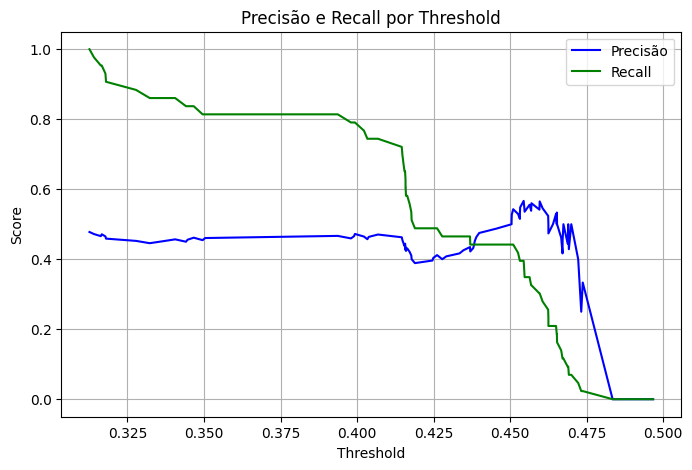

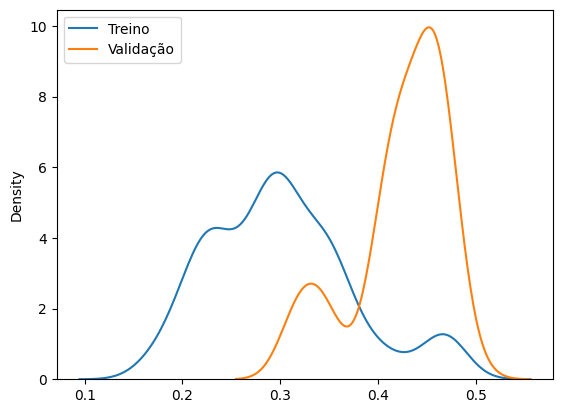

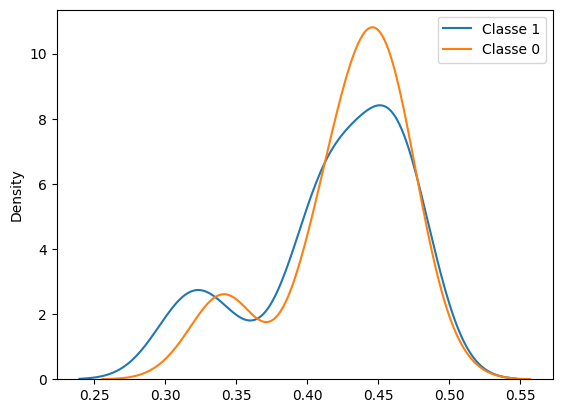

In [11]:
resultado = treinar_e_validar_modelo(X_train, y_train, X_validacao, y_validacao, dias_janela=60, dias_validacao=90, threshold=0.65, class_weight={0:2, 1:1})
modelo = resultado['modelo']
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']


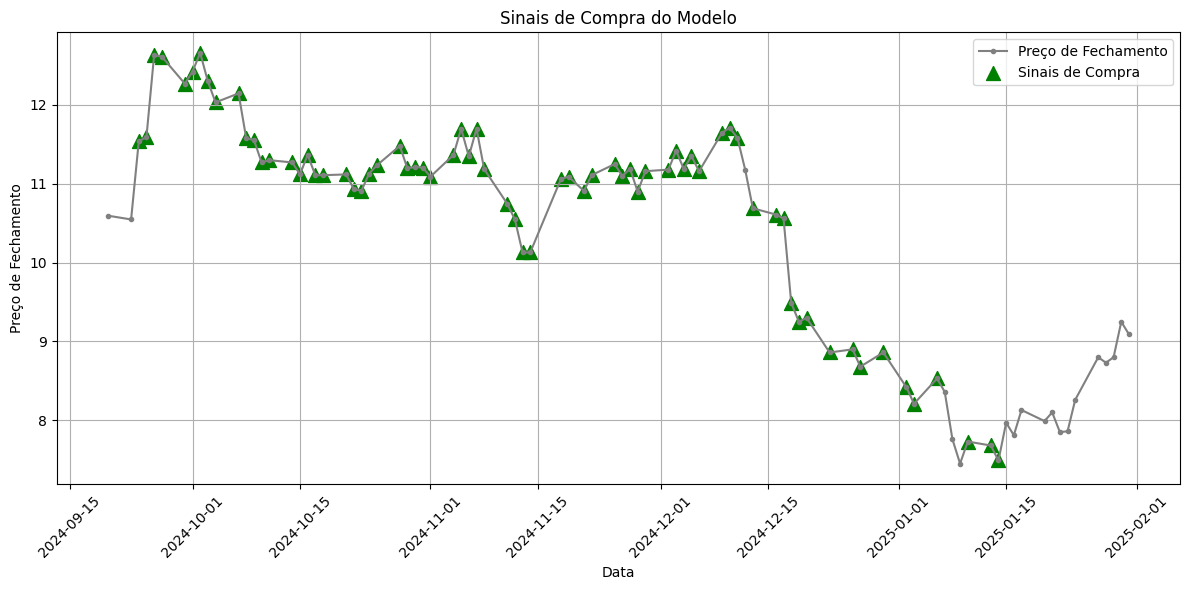

In [12]:
plotar_sinal_compras(modelo, df, X_validacao, dias_janela=DIAS_JANELA_X, dias_validacao=DIAS_VALIDACAO, threshold=0.4)

In [13]:
def executar_experimentos(df, thresholds, pesos_classes, dias_janela=60, dias_validacao=90):
    resultados = []

    for threshold in thresholds:
        for pesos in pesos_classes:
            print(f"\n>>> Testando: threshold={threshold}, class_weight={pesos}")
            resultado = treinar_e_validar_modelo(
                X, y,
                dias_janela=dias_janela,
                dias_validacao=dias_validacao,
                threshold=threshold,
                class_weight=pesos
            )

            resultados.append({
                'threshold_utilizado': threshold,
                'threshold_calibrado': resultado['threshold_calibrado'],
                'class_weight': pesos,
                'modelo': resultado['modelo'],
                'probas': resultado['probas_validacao'],
                'y_true': resultado['y_validacao'],
                'y_pred': resultado['y_pred_validacao']                
            })

    return resultados

def extrair_metricas(resultados):
    registros = []
    for r in resultados:
        acuracia = accuracy_score(r['y_true'], r['y_pred'])
        precisao = precision_score(r['y_true'], r['y_pred'], zero_division=0)
        recall = recall_score(r['y_true'], r['y_pred'], zero_division=0)

        registros.append({
            'threshold_utilizado': r['threshold_utilizado'],
            'threshold_calibrado': r['threshold_calibrado'],
            'class_weight': r['class_weight'],
            'acuracia': acuracia,
            'precisao': precisao,
            'recall': recall
        })

    return pd.DataFrame(registros)

In [14]:
resultados = executar_experimentos(
    df,
    thresholds=[0.5, 0.55, 0.6, 0.7, 0.8],
    pesos_classes=[{0: 1, 1: 1}, {0: 2, 1: 1}, {0: 3, 1: 1}]
)



>>> Testando: threshold=0.5, class_weight={0: 1, 1: 1}


TypeError: treinar_e_validar_modelo() missing 2 required positional arguments: 'X_validacao' and 'y_validacao'

In [ ]:
df_resultados = extrair_metricas(resultados)
df_resultados.sort_values(by='precisao', ascending=False)


,threshold_utilizado,threshold_calibrado,class_weight,acuracia,precisao,recall
7,0.60,0.628365,"{0: 2, 1: 1}",0.655556,0.750000,0.418605
4,0.55,0.628365,"{0: 2, 1: 1}",0.611111,0.576923,0.697674
12,0.80,0.993332,"{0: 1, 1: 1}",0.511111,0.494253,1.000000
6,0.60,0.993332,"{0: 1, 1: 1}",0.477778,0.477778,1.000000
9,0.70,0.993332,"{0: 1, 1: 1}",0.477778,0.477778,1.000000
3,0.55,0.993332,"{0: 1, 1: 1}",0.477778,0.477778,1.000000
0,0.50,0.993332,"{0: 1, 1: 1}",0.477778,0.477778,1.000000
1,0.50,0.628365,"{0: 2, 1: 1}",0.477778,0.471429,0.767442
2,0.50,0.442621,"{0: 3, 1: 1}",0.522222,0.000000,0.000000
5,0.55,0.442621,"{0: 3, 1: 1}",0.522222,0.000000,0.000000


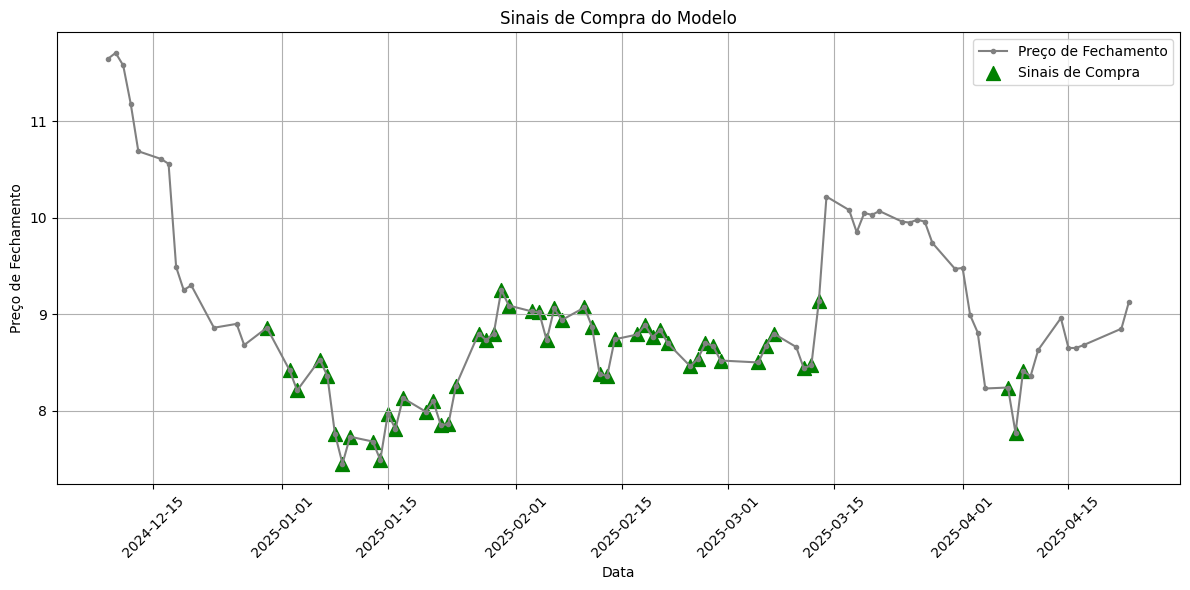

In [ ]:
modelo = resultados[7]['modelo']
plotar_sinal_compras(modelo, df, dias_janela=DIAS_JANELA_X, dias_validacao=DIAS_VALIDACAO, threshold=0.55)

In [ ]:
resultados[14]

{'threshold_utilizado': 0.8,
 'threshold_calibrado': np.float64(0.44262058767803364),
 'class_weight': {0: 3, 1: 1},
 'modelo': LogisticRegression(class_weight={0: 3, 1: 1}, max_iter=1000, solver='liblinear'),
 'probas': array([0.22864008, 0.25342871, 0.25283232, 0.35212514, 0.36611506,
        0.37071591, 0.38739005, 0.38851247, 0.41485646, 0.41109866,
        0.38312678, 0.44250921, 0.43632123, 0.43255003, 0.45582051,
        0.47416636, 0.47081353, 0.47488212, 0.48055098, 0.47124304,
        0.4581895 , 0.45288466, 0.45559948, 0.45420911, 0.45789751,
        0.45879594, 0.45078247, 0.44262059, 0.42936701, 0.42797006,
        0.4236322 , 0.42670458, 0.42749602, 0.42817849, 0.42193926,
        0.40306915, 0.40451161, 0.40190262, 0.40352218, 0.41066513,
        0.40824143, 0.39310333, 0.38525732, 0.37752876, 0.37626268,
        0.37058012, 0.36980254, 0.36424628, 0.35947434, 0.35526894,
        0.35480738, 0.35843782, 0.35767786, 0.35233022, 0.34733344,
        0.35026223, 0.35358459, 


--- Conjunto de Treino ---

Relatório de Validação (threshold = 0.5):
              precision    recall  f1-score   support

         0.0       0.53      1.00      0.69       242
         1.0       0.00      0.00      0.00       217

    accuracy                           0.53       459
   macro avg       0.26      0.50      0.35       459
weighted avg       0.28      0.53      0.36       459

Acurácia: 0.5272331154684096
Precisão (classe 1): 0.0
Recall (classe 1): 0.0

Threshold ideal baseado em recall mínimo (não usado na validação abaixo): 0.44

--- Conjunto de Validação ---

Relatório de Validação (threshold = 0.98):
              precision    recall  f1-score   support

         0.0       0.52      1.00      0.69        47
         1.0       0.00      0.00      0.00        43

    accuracy                           0.52        90
   macro avg       0.26      0.50      0.34        90
weighted avg       0.27      0.52      0.36        90

Acurácia: 0.5222222222222223
Precisão (clas

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c

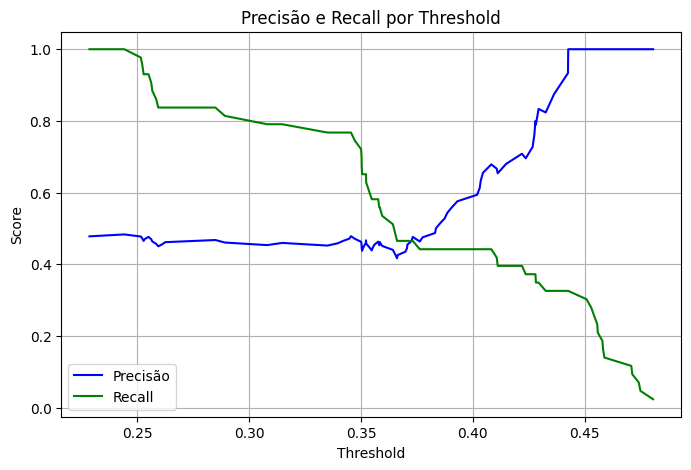

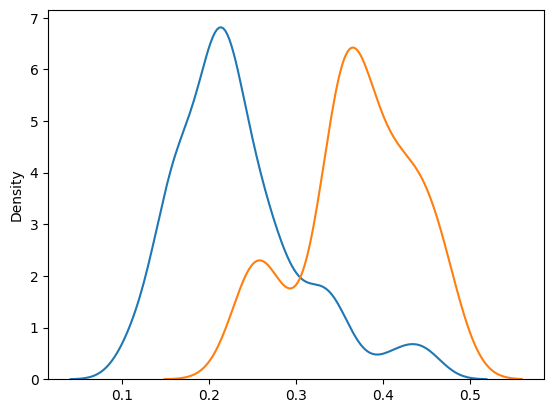

In [ ]:
r = treinar_e_validar_modelo(
                X, y,
                dias_janela=DIAS_VALIDACAO,
                dias_validacao=DIAS_VALIDACAO,
                threshold=0.98,
                class_weight={0:3, 1:1}
            )

# Seleção de features

## top N variaveis mais importantes

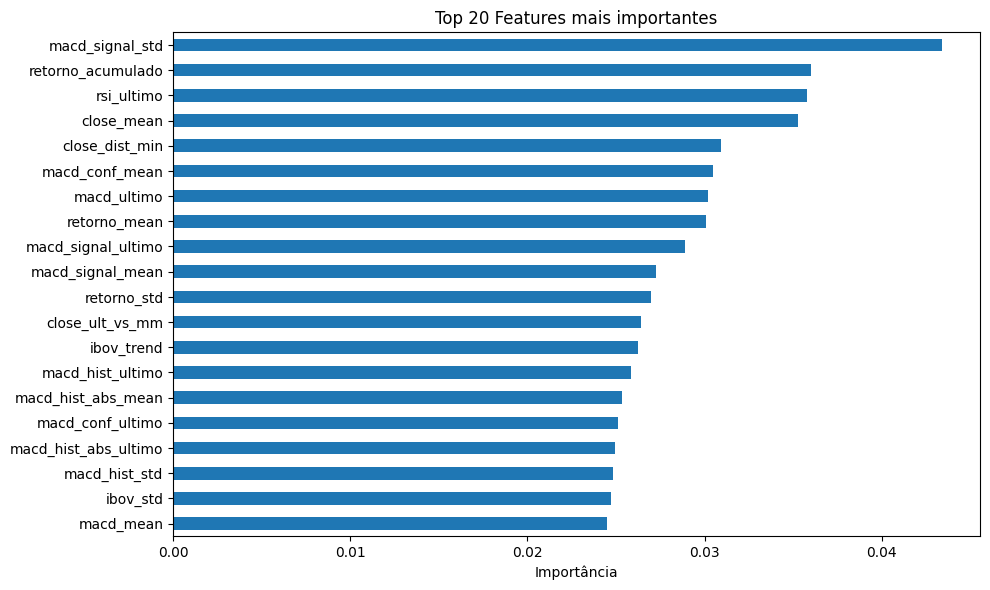

In [ ]:
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import matplotlib.pyplot as plt

X_train, y_train, X_validacao, y_validacao = dividir_treino_validacao(X, y, dias_validacao=DIAS_VALIDACAO)

# Treinamento
modelo = RandomForestClassifier(n_estimators=100, random_state=42)
modelo.fit(X_train, y_train)

# Importâncias
importancias = pd.Series(modelo.feature_importances_, index=X.columns)
importancias = importancias.sort_values(ascending=False)

# Visualizar top 20
plt.figure(figsize=(10, 6))
importancias.head(20).plot(kind='barh')
plt.gca().invert_yaxis()
plt.title('Top 20 Features mais importantes')
plt.xlabel('Importância')
plt.tight_layout()
plt.show()


## Validação com janela deslizante e precisão média

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score
import numpy as np

def avaliar_precision_janelas(X_train, y_train, X_valid, y_valid, colunas_selecionadas=None, janela_treino=180, janela_teste=30):
    precisões = []

    for i in range(0, len(X_valid) - janela_teste):
        X_val_teste = X_valid.iloc[i:i + janela_teste]
        y_val_teste = y_valid.iloc[i:i + janela_teste]

        if colunas_selecionadas:
            X_treino_modelo = X_train[colunas_selecionadas]
            X_val_teste = X_val_teste[colunas_selecionadas]
        else:
            X_treino_modelo = X_train

        modelo = RandomForestClassifier(n_estimators=100, random_state=42)
        modelo.fit(X_treino_modelo, y_train)
        y_pred = modelo.predict(X_val_teste)

        try:
            prec = precision_score(y_val_teste, y_pred, zero_division=0, average='binary', pos_label=1)
            precisões.append(prec)
        except Exception as e:
            print(f"Erro na janela {i}: {e}")

    print(f"Precisão média: {np.mean(precisões):.4f}")
    return precisões


In [ ]:
precisoes_completas = avaliar_precision_janelas(X_train, y_train, X_validacao, y_validacao)

Precisão média: 0.6917


In [ ]:
modelo_importancia = RandomForestClassifier(n_estimators=100, random_state=42)
modelo_importancia.fit(X_train, y_train)
importancias = pd.Series(modelo_importancia.feature_importances_, index=X_train.columns).sort_values(ascending=False)
colunas_top = importancias.head(10).index.tolist()

precisoes_top = avaliar_precision_janelas(X_train, y_train, X_validacao, y_validacao, colunas_selecionadas=colunas_top)


Precisão média: 0.5992


In [ ]:
importancias.shape

(43,)

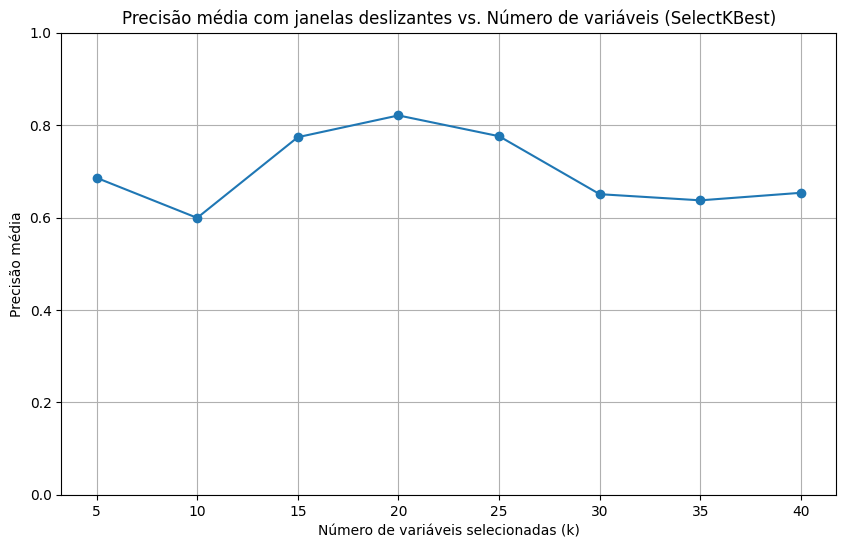

In [ ]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

def avaliar_precisao_por_k_janelas(X_train, y_train, X_valid, y_valid, k_values, importancias, janela_treino=180, janela_teste=30):
    resultados = {}

    for k in k_values:        
        colunas_selecionadas = importancias.head(k).index.tolist()        
        precisões = []

        for i in range(0, len(X_valid) - janela_teste):
            X_val_teste = X_valid.iloc[i:i + janela_teste][colunas_selecionadas]
            y_val_teste = y_valid.iloc[i:i + janela_teste]

            modelo = RandomForestClassifier(n_estimators=100, random_state=42)
            modelo.fit(X_train[colunas_selecionadas], y_train)

            y_pred = modelo.predict(X_val_teste)
            prec = precision_score(y_val_teste, y_pred, zero_division=0)
            precisões.append(prec)

        resultados[k] = np.mean(precisões)

    return resultados

# Altere se quiser outro intervalo de k
k_values = list(range(5, min(51, X_train.shape[1] + 1), 5))
resultados = avaliar_precisao_por_k_janelas(X_train, y_train, X_validacao, y_validacao, k_values, importancias)

plt.figure(figsize=(10, 6))
plt.plot(resultados.keys(), resultados.values(), marker='o')
plt.title("Precisão média com janelas deslizantes vs. Número de variáveis (RandomForest Importance)")
plt.xlabel("Número de variáveis selecionadas (k)")
plt.ylabel("Precisão média")
plt.ylim(0, 1)
plt.grid(True)
plt.show()


## Teste do modelo com variáveis reduzidas

In [ ]:
lista_colunas_selecionadas = importancias.head(20).index.tolist()
lista_colunas_selecionadas

['macd_signal_std',
 'retorno_acumulado',
 'rsi_ultimo',
 'close_mean',
 'close_dist_min',
 'macd_conf_mean',
 'macd_ultimo',
 'retorno_mean',
 'macd_signal_ultimo',
 'macd_signal_mean',
 'retorno_std',
 'close_ult_vs_mm',
 'ibov_trend',
 'macd_hist_ultimo',
 'macd_hist_abs_mean',
 'macd_conf_ultimo',
 'macd_hist_abs_ultimo',
 'macd_hist_std',
 'ibov_std',
 'macd_mean']

In [ ]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [ ]:
X_validacao_reduzido.columns

Index(['macd_signal_std', 'retorno_acumulado', 'rsi_ultimo', 'close_mean',
       'close_dist_min', 'macd_conf_mean', 'macd_ultimo', 'retorno_mean',
       'macd_signal_ultimo', 'macd_signal_mean', 'retorno_std',
       'close_ult_vs_mm', 'ibov_trend', 'macd_hist_ultimo',
       'macd_hist_abs_mean', 'macd_conf_ultimo', 'macd_hist_abs_ultimo',
       'macd_hist_std', 'ibov_std', 'macd_mean'],
      dtype='object')

In [ ]:
X_train_reduzido.columns

Index(['macd_signal_std', 'retorno_acumulado', 'rsi_ultimo', 'close_mean',
       'close_dist_min', 'macd_conf_mean', 'macd_ultimo', 'retorno_mean',
       'macd_signal_ultimo', 'macd_signal_mean', 'retorno_std',
       'close_ult_vs_mm', 'ibov_trend', 'macd_hist_ultimo',
       'macd_hist_abs_mean', 'macd_conf_ultimo', 'macd_hist_abs_ultimo',
       'macd_hist_std', 'ibov_std', 'macd_mean'],
      dtype='object')


--- Conjunto de Treino --- Geral

Relatório de Validação (threshold = 0.4):
              precision    recall  f1-score   support

         0.0       0.54      0.97      0.69       246
         1.0       0.47      0.03      0.06       211

    accuracy                           0.54       457
   macro avg       0.50      0.50      0.38       457
weighted avg       0.51      0.54      0.40       457

Acurácia: 0.5361050328227571
Precisão (classe 1): 0.4666666666666667
Recall (classe 1): 0.03317535545023697
AUC no treino: 0.601

--- Conjunto de Treino --- Janelas
→ Threshold calibrado para recall ≥ 0.1: 0.34

Avaliação com Janela Deslizante (60 dias):
Precisão média (em 269 janelas com previsão positiva): 0.550
Recall médio: 0.273
Acurácia média: 0.607

Threshold ideal baseado em recall mínimo (não usado na validação abaixo): 0.55

--- Conjunto de Validação --- Geral

Relatório de Validação (threshold = 0.55):
              precision    recall  f1-score   support

         0.0       0.5

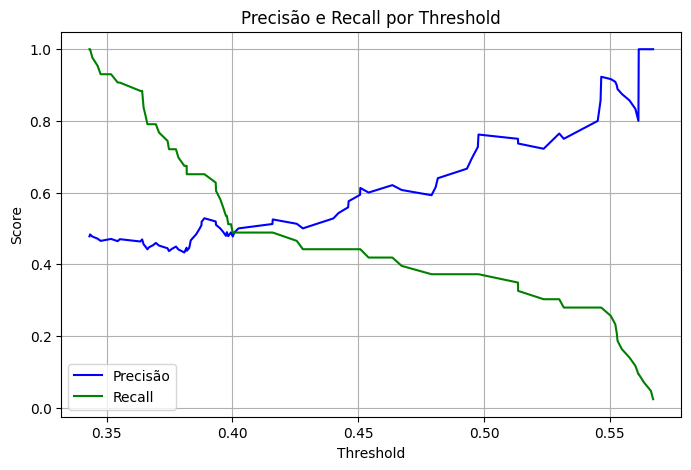

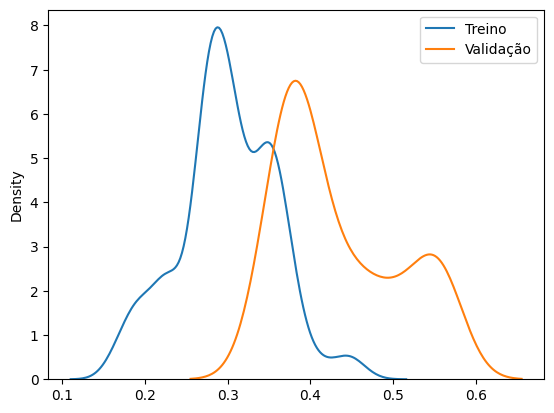

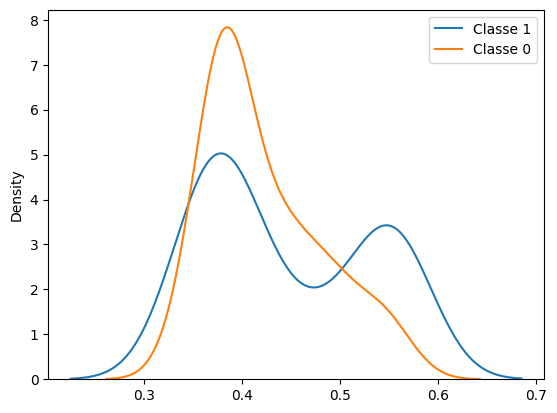

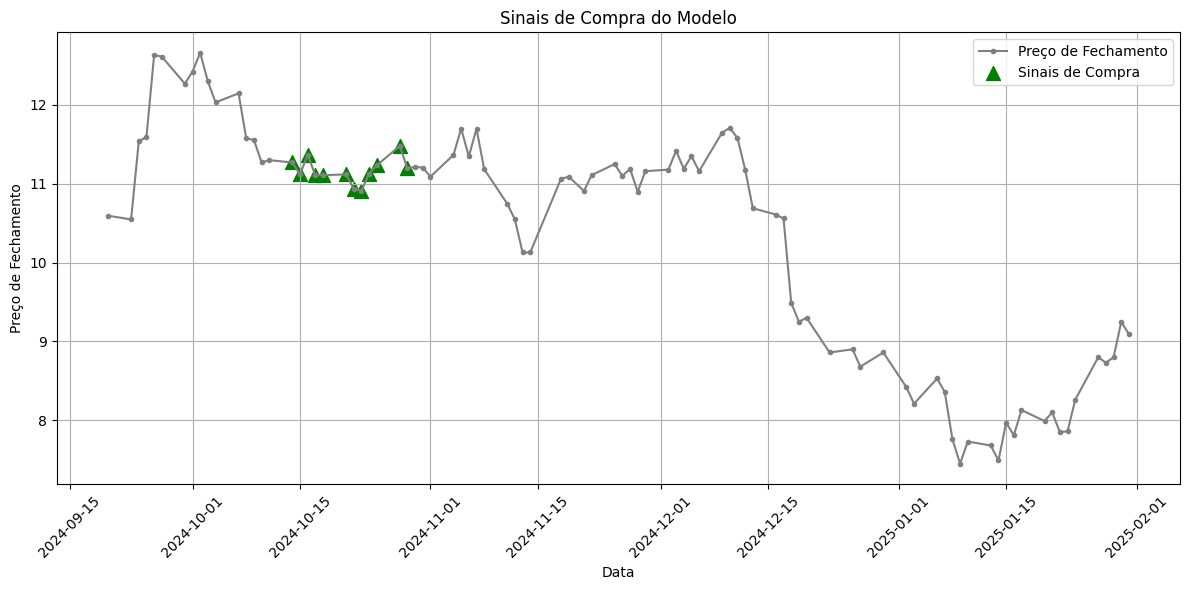

In [ ]:
resultado = treinar_e_validar_modelo(X_train_reduzido, y_train, X_validacao_reduzido, y_validacao,dias_janela=60, dias_validacao=90, threshold=0.55, class_weight={0:2, 1:1}, window_size=60)
modelo = resultado['modelo']
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']
plotar_sinal_compras(modelo, df, X_validacao_reduzido,dias_janela=DIAS_JANELA_X, dias_validacao=DIAS_VALIDACAO, threshold=0.55)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def plotar_precisao_por_faixa(probas, y_true, bins=np.arange(0, 1.01, 0.1)):
    """
    Plota a precisão empírica por faixa de probabilidade prevista.
    
    probas: array com as probabilidades previstas (classe positiva)
    y_true: array com os rótulos reais (0 ou 1)
    bins: intervalos de probabilidade
    """
    df = pd.DataFrame({
        'proba': probas,
        'real': y_true
    })

    df['faixa'] = pd.cut(df['proba'], bins=bins, include_lowest=True)
    resumo = df.groupby('faixa').agg(
        total=('real', 'count'),
        positivos=('real', 'sum')
    )
    resumo['precisao_empirica'] = resumo['positivos'] / resumo['total']

    resumo = resumo.dropna()

    plt.figure(figsize=(10, 5))
    plt.bar(resumo.index.astype(str), resumo['precisao_empirica'], color='steelblue')
    plt.xticks(rotation=45)
    plt.ylim(0, 1)
    plt.title('Precisão Empírica por Faixa de Probabilidade Prevista')
    plt.ylabel('Precisão')
    plt.xlabel('Faixa de Probabilidade Prevista')
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

# Exemplo de uso com suas variáveis:
# probas_validacao = modelo.predict_proba(X_validacao.values)[:, 1]
# y_validacao = y_validacao.values

C:\Users\fsbertaggia\AppData\Local\Temp\ipykernel_22916\1785903605.py:19: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  resumo = df.groupby('faixa').agg(


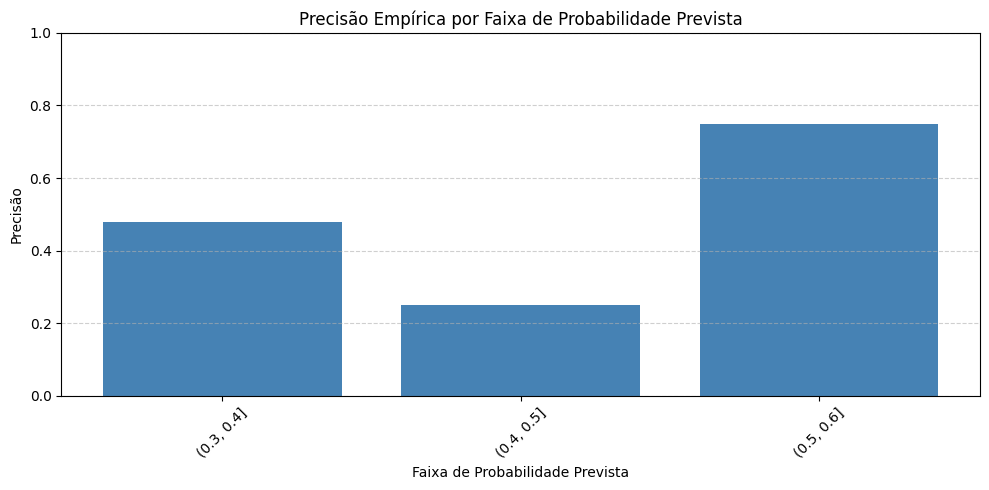

In [ ]:
probas_validacao = resultado['probas_validacao']
plotar_precisao_por_faixa(probas_validacao, y_validacao)